In [ ]:
# 🔴 clean install of compatible stack

!pip uninstall -y keras tf-keras tensorflow tensorflow-probability

!pip install -q \
    tensorflow==2.19.0 \
    tensorflow-probability==0.25.0 \
    tf-keras==2.19.0

Found existing installation: keras 3.10.0
Uninstalling keras-3.10.0:
  Successfully uninstalled keras-3.10.0
Found existing installation: tf_keras 2.19.0
Uninstalling tf_keras-2.19.0:
  Successfully uninstalled tf_keras-2.19.0
Found existing installation: tensorflow 2.19.0
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
             ^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/commands/uninstall.py", line 106, in run
    uninstall_pathset = req.uninstall(
                        ^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/req/req_install.py", line 721, in uninstall
    uninstalled_pathset = UninstallPathSet.from_dist(dist)
                          ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/req/req_uninstall.py", line 518, in from_dist
   

In [ ]:
import tensorflow as tf
import tensorflow_probability as tfp
import tf_keras

print("TF:", tf.__version__)
print("TFP:", tfp.__version__)
print("tf_keras:", tf_keras.__version__)

print("keras module:", tf.keras)

TF: 2.19.0
TFP: 0.25.0
tf_keras: 2.19.0
keras module: <KerasLazyLoader>


In [ ]:
#!pip uninstall -y tensorflow tensorflow-probability tf-keras keras
#!pip install tensorflow==2.19.0 tensorflow-probability[tf]

In [ ]:
#!pip install -q tf-keras==2.16.0

In [ ]:
# clean install compatible stack
#!pip uninstall -y tensorflow tensorflow-probability keras tf-keras
#!pip install -q tensorflow==2.16.1 tensorflow-probability==0.24.0

In [ ]:
#!pip install tf-keras

In [ ]:
#!pip install -U ml-dtypes

In [ ]:
#!pip install tensorflow_probability

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("Flood Data.csv")

print("Shape:", df.shape)
print("\nMissing values per column:")
print(df.isna().sum())


Shape: (67330, 16)

Missing values per column:
ROW                     0
X                       0
Y                       0
HAZARD 1 IN 30          0
HAZARD 1 IN 100         0
HAZARD 1 IN 1000        0
ELEVATION             797
SLOPE                 998
LANDUSE               866
IMPERVIOUSNESS        678
LITHOLOGY             748
SUBSTRATE             748
NDVI                  905
DISTANCE TO RIVER    1012
BUILDING TYPE         793
DISTANCE TO ROAD     1012
dtype: int64


In [ ]:
target_col = "HAZARD 1 IN 100"

# target
y = df[target_col]

# drop leakage + non-features
drop_cols = [
    "ROW", "X", "Y",
    "HAZARD 1 IN 30",
    "HAZARD 1 IN 100",
    "HAZARD 1 IN 1000"
]

X = df.drop(columns=drop_cols)


In [ ]:
mask = ~y.isna()

X = X[mask]
y = y[mask]

print("After removing missing targets:", X.shape)


After removing missing targets: (67330, 10)


In [ ]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="mean")
X_imputed = imputer.fit_transform(X)

In [ ]:
clean_df = pd.DataFrame(X_imputed, columns=X.columns)
clean_df[target_col] = y.values

clean_df.to_csv("Flood_Data_Cleaned.csv", index=False)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_imputed,   # ← MUST be this
    y.values,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [ ]:
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(X_train, y_train)

# select top 10 features
k = 10
top_idx = np.argsort(mi)[-k:]

X_train_fs = X_train[:, top_idx]
X_test_fs = X_test[:, top_idx]

print("Selected feature indices:", top_idx)


Selected feature indices: [6 1 9 3 2 8 0 5 4 7]


In [ ]:
print("NaNs in y_train:", np.isnan(y_train).sum())
print("NaNs in X_train:", np.isnan(X_train).sum())

NaNs in y_train: 0
NaNs in X_train: 0


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# load
df = pd.read_csv("Flood_Data_Cleaned.csv")

# assume last column is label
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

# scale features (IMPORTANT)
scaler = StandardScaler()
X = scaler.fit_transform(X)

# split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


Variational Inference

In [ ]:
# example: class 0 = no flood, others = flood
#y_binary = (y > 0).astype(int)


In [ ]:
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(X_train, y_train)

# select top k
k = 10
top_idx = np.argsort(mi)[-k:]
X_train_fs = X_train[:, top_idx]
X_test_fs = X_test[:, top_idx]

X_train = X_train_fs.astype("float32")
X_test = X_test_fs.astype("float32")


In [ ]:
#X_train = X_train.astype("float32")
#X_test = X_test.astype("float32")

import tensorflow as tf
import tensorflow_probability as tfp

tf.keras.backend.set_floatx('float32')

keras = tf.keras   # 🔴 THIS IS THE FIX
tfpl = tfp.layers
tfd = tfp.distributions

num_classes = len(np.unique(y_train))

baseline = keras.Sequential([
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(num_classes, activation='softmax')
])

baseline.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

baseline.fit(X_train_fs, y_train, epochs=50, verbose=0)


In [ ]:
#print(type(inputs), inputs.shape)

In [ ]:
import tensorflow as tf
import tensorflow_probability as tfp
import numpy as np

keras = tf.keras
tfpl = tfp.layers
tfd = tfp.distributions


X_train_fs = X_train_fs.astype(np.float32)
X_test_fs = X_test_fs.astype(np.float32)
y_train = y_train.astype(np.int32)
y_test = y_test.astype(np.int32)

kl_weight = 1.0 / float(X_train_fs.shape[0])
num_classes = len(np.unique(y_train))


# ---------- Posterior ----------
def posterior(kernel_size, bias_size=0, dtype=None):
    n = kernel_size + bias_size
    return keras.Sequential([
        tfpl.VariableLayer(2 * n, dtype=dtype),
        tfpl.DistributionLambda(
            lambda t: tfd.Independent(
                tfd.Normal(
                    loc=t[..., :n],
                    scale=1e-5 + tf.nn.softplus(t[..., n:])
                ),
                reinterpreted_batch_ndims=1,
            )
        ),
    ])


# ---------- Prior ----------
def prior(kernel_size, bias_size=0, dtype=None):
    n = kernel_size + bias_size

    def prior_fn(_):
        return tfd.Independent(
            tfd.Normal(
                loc=tf.zeros(n, dtype=dtype),
                scale=1.0,
            ),
            reinterpreted_batch_ndims=1,
        )

    return keras.Sequential([
        tfpl.DistributionLambda(prior_fn)
    ])

# ---------- Model ----------
inputs = keras.Input(shape=(X_train_fs.shape[1],), dtype=tf.float32)

x = tfpl.DenseVariational(
    units=32,
    make_prior_fn=prior,
    make_posterior_fn=posterior,
    kl_weight=kl_weight,
    activation="relu",
)(inputs)

outputs = tfpl.DenseVariational(
    units=num_classes,
    make_prior_fn=prior,
    make_posterior_fn=posterior,
    kl_weight=kl_weight,
    activation="softmax",
)(x)

bnn_vi = keras.Model(inputs=inputs, outputs=outputs)

print("✅ BNN built successfully")

✅ BNN built successfully


In [ ]:
def predict_vi_uncertainty(model, X, n_samples=50):
    probs = np.array([model(X).numpy() for _ in range(n_samples)])

    mean_prob = probs.mean(axis=0)

    # predictive entropy
    entropy = -np.sum(mean_prob * np.log(mean_prob + 1e-8), axis=1)

    return mean_prob, entropy

vi_probs, vi_entropy = predict_vi_uncertainty(bnn_vi, X_test)


In [ ]:
# Predicted labels
vi_pred = np.argmax(vi_probs, axis=1)

# Accuracy
vi_accuracy = np.mean(vi_pred == y_test)

print(f"✅ VI Test Accuracy: {vi_accuracy:.4f}")
print(f"✅ Mean Predictive Entropy: {vi_entropy.mean():.4f}")
print(f"✅ Max Entropy: {vi_entropy.max():.4f}")
print(f"✅ Min Entropy: {vi_entropy.min():.4f}")

✅ VI Test Accuracy: 0.1961
✅ Mean Predictive Entropy: 1.5732
✅ Max Entropy: 1.6090
✅ Min Entropy: 1.4786


MCMC classification

In [ ]:
import tensorflow as tf
import tensorflow_probability as tfp
import numpy as np

tfd = tfp.distributions

# ensure float32
X_train_tf = tf.constant(X_train, dtype=tf.float32)
y_train_tf = tf.constant(y_train, dtype=tf.int32)

num_features = X_train.shape[1]
num_classes = len(np.unique(y_train))


In [ ]:
n_hidden = 8  # keep small for MCMC!

In [ ]:
def joint_log_prob(w0, b0, w1, b1):
    # ----- Priors -----
    rv_w0 = tfd.Normal(0., 1.)
    rv_b0 = tfd.Normal(0., 1.)
    rv_w1 = tfd.Normal(0., 1.)
    rv_b1 = tfd.Normal(0., 1.)

    # ----- Forward pass -----
    hidden = tf.nn.relu(tf.matmul(X_train_tf, w0) + b0)
    logits = tf.matmul(hidden, w1) + b1

    # ----- Likelihood (Categorical!) -----
    rv_y = tfd.Categorical(logits=logits)

    log_likelihood = tf.reduce_sum(rv_y.log_prob(y_train_tf))

    # ----- Total log posterior -----
    return (
        tf.reduce_sum(rv_w0.log_prob(w0)) +
        tf.reduce_sum(rv_b0.log_prob(b0)) +
        tf.reduce_sum(rv_w1.log_prob(w1)) +
        tf.reduce_sum(rv_b1.log_prob(b1)) +
        log_likelihood
    )


In [ ]:
initial_state = [
    tf.random.normal([num_features, n_hidden]),  # w0
    tf.random.normal([n_hidden]),                # b0
    tf.random.normal([n_hidden, num_classes]),   # w1
    tf.random.normal([num_classes])              # b1
]


In [ ]:
num_results = 300
num_burnin = 200

hmc_kernel = tfp.mcmc.HamiltonianMonteCarlo(
    target_log_prob_fn=joint_log_prob,
    step_size=0.005,
    num_leapfrog_steps=3
)

# optional but recommended
hmc_kernel = tfp.mcmc.SimpleStepSizeAdaptation(
    hmc_kernel,
    num_adaptation_steps=int(num_burnin * 0.8)
)


In [ ]:
states, kernel_results = tfp.mcmc.sample_chain(
    num_results=num_results,
    num_burnin_steps=num_burnin,
    current_state=initial_state,
    kernel=hmc_kernel,
    trace_fn=lambda current_state, kernel_results: kernel_results
)

In [ ]:
def predict_mcmc(states, X):
    X_tf = tf.constant(X, dtype=tf.float32)

    w0_s, b0_s, w1_s, b1_s = states
    probs_samples = []

    for i in range(len(w0_s)):
        hidden = tf.nn.relu(tf.matmul(X_tf, w0_s[i]) + b0_s[i])
        logits = tf.matmul(hidden, w1_s[i]) + b1_s[i]
        probs = tf.nn.softmax(logits)
        probs_samples.append(probs.numpy())

    probs_samples = np.array(probs_samples)

    mean_probs = probs_samples.mean(axis=0)

    # predictive entropy
    entropy = -np.sum(mean_probs * np.log(mean_probs + 1e-8), axis=1)

    preds = np.argmax(mean_probs, axis=1)

    return preds, mean_probs, entropy


In [ ]:
from sklearn.metrics import accuracy_score

mcmc_preds, mcmc_probs, mcmc_entropy = predict_mcmc(states, X_test)

acc = accuracy_score(y_test, mcmc_preds)
print("MCMC Accuracy:", acc)

print(f" Mean Predictive Entropy: {mcmc_entropy.mean():.4f}")
print(f" Max Entropy: {mcmc_entropy.max():.4f}")
print(f" Min Entropy: {mcmc_entropy.min():.4f}")


MCMC Accuracy: 0.9809148967770682
 Mean Predictive Entropy: 0.0848
 Max Entropy: 1.3084
 Min Entropy: 0.0000


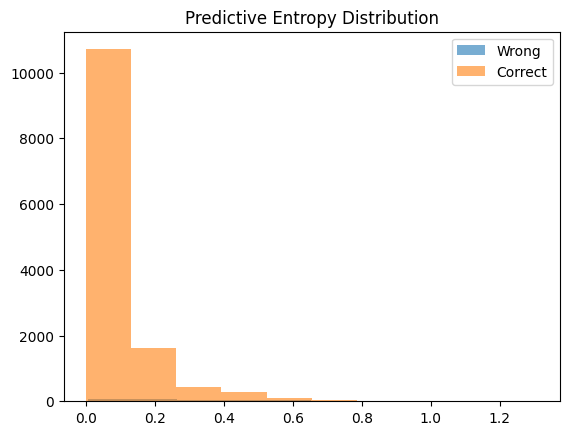

In [ ]:
errors = (mcmc_preds != y_test)

import matplotlib.pyplot as plt

plt.hist(mcmc_entropy[errors], alpha=0.6, label="Wrong")
plt.hist(mcmc_entropy[~errors], alpha=0.6, label="Correct")
plt.legend()
plt.title("Predictive Entropy Distribution")
plt.show()
